In [1]:
import os
import glob
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.transforms as transforms

# Dataset Path
DATASET_PATH = r"C:\Users\MADHUSHALNE\DATASET ML\140K Real and Fake Faces dataset\real_vs_fake\real-vs-fake"

print("=" * 60)
print(f"Dataset Path:     {DATASET_PATH}")
print(f"Directory Exists: {os.path.exists(DATASET_PATH)}")
print(f"PyTorch Version:  {torch.__version__}")
print(f"CUDA Available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:       {torch.cuda.get_device_name(0)}")
print("=" * 60)


Dataset Path:     C:\Users\MADHUSHALNE\DATASET ML\140K Real and Fake Faces dataset\real_vs_fake\real-vs-fake
Directory Exists: True
PyTorch Version:  2.11.0+cu126
CUDA Available:   True
GPU Device:       NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [2]:
# ==============================================================================
# 1. RAW IMAGE DIMENSION INSPECTION
# ==============================================================================
# Inspect actual dimensions and formats of sample images directly from disk
sample_folders = [
    os.path.join(DATASET_PATH, "train", "real"),
    os.path.join(DATASET_PATH, "train", "fake"),
    os.path.join(DATASET_PATH, "valid", "real"),
    os.path.join(DATASET_PATH, "valid", "fake"),
    os.path.join(DATASET_PATH, "test", "real"),
    os.path.join(DATASET_PATH, "test", "fake"),
]

print(f"\n{'Split / Class':<20} | {'Filename':<25} | {'Actual (W x H)':<18} | {'Mode':<6} | {'Format':<8} | {'File Size'}")
print("-" * 95)

for folder in sample_folders:
    if not os.path.exists(folder):
        print(f"Folder not found: {folder}")
        continue
        
    split_name = os.path.relpath(folder, DATASET_PATH)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))][:1]
    
    if not files:
        print(f"{split_name:<20} | {'(No images found)':<25} | {'-':<18} | {'-':<6} | {'-':<8} | -")
        continue
        
    for fname in files:
        fpath = os.path.join(folder, fname)
        with Image.open(fpath) as img:
            w, h = img.size
            mode = img.mode
            fmt = img.format
            size_kb = os.path.getsize(fpath) / 1024
            print(f"{split_name:<20} | {fname[:24]:<25} | {f'{w} x {h} px':<18} | {mode:<6} | {fmt:<8} | {size_kb:.1f} KB")



Split / Class        | Filename                  | Actual (W x H)     | Mode   | Format   | File Size
-----------------------------------------------------------------------------------------------
train\real           | 00000.jpg                 | 256 x 256 px       | RGB    | JPEG     | 26.9 KB
train\fake           | 001DDU0NI4.jpg            | 256 x 256 px       | RGB    | JPEG     | 24.4 KB
valid\real           | 00005.jpg                 | 256 x 256 px       | RGB    | JPEG     | 25.2 KB
valid\fake           | 00483R5CC4.jpg            | 256 x 256 px       | RGB    | JPEG     | 21.3 KB
test\real            | 00001.jpg                 | 256 x 256 px       | RGB    | JPEG     | 29.3 KB
test\fake            | 00276TOPP4.jpg            | 256 x 256 px       | RGB    | JPEG     | 27.4 KB


In [3]:
# ==============================================================================
# 2. SET IMG_SIZE & SCAN STATISTICAL RESOLUTION DISTRIBUTION
# ==============================================================================
# Set IMG_SIZE based on inspected sample images
IMG_SIZE = 256  # Standard resolution (matches raw 256x256 image dimensions)
print(f"Selected IMG_SIZE: {IMG_SIZE} x {IMG_SIZE} px")

# Scan resolution distribution across sample dataset images
sample_size = 300  # Number of images to check per class per split
resolution_counts = Counter()

for s in ["train", "valid", "test"]:
    for c in ["real", "fake"]:
        target_dir = os.path.join(DATASET_PATH, s, c)
        if not os.path.exists(target_dir):
            continue
            
        all_imgs = [f for f in os.listdir(target_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]
        selected_imgs = all_imgs[:sample_size]
        
        for fname in selected_imgs:
            fpath = os.path.join(target_dir, fname)
            try:
                with Image.open(fpath) as img:
                    res = f"{img.width} x {img.height}"
                    resolution_counts[res] += 1

            except Exception as e:
                print(f"[!] Error reading {fpath}: {e}")

total_scanned = sum(resolution_counts.values())
if total_scanned > 0:
    print(f"\nScanned {total_scanned:,} images across the dataset.")
    print("Resolution Distribution:")
    for res, count in resolution_counts.most_common():
        percentage = (count / total_scanned) * 100
        print(f"  {res} pixels : {count} images ({percentage:.1f}%)")
else:
    print("[!] No images found to scan. Please verify DATASET_PATH.")


Selected IMG_SIZE: 256 x 256 px

Scanned 1,800 images across the dataset.
Resolution Distribution:
  256 x 256 pixels : 1800 images (100.0%)


Split      | Real       | Fake       | Total     
------------------------------------------------
train      | 50,000     | 50,000     | 100,000   
valid      | 10,000     | 10,000     | 20,000    
test       | 10,000     | 10,000     | 20,000    


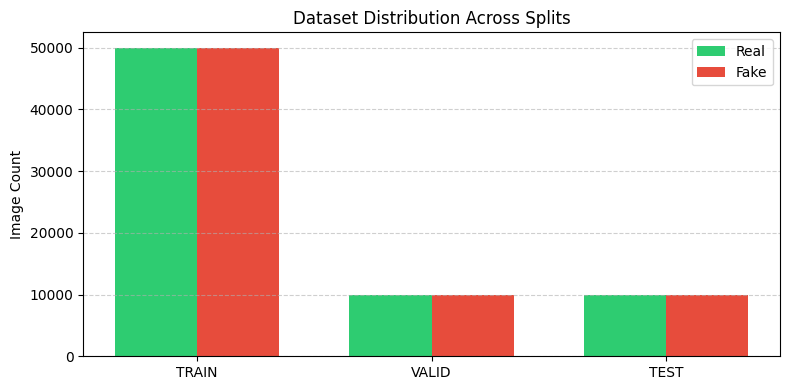

In [4]:
# ==============================================================================
# 3. DATASET DIRECTORY STRUCTURE & IMAGE COUNTS
# ==============================================================================
splits = ["train", "valid", "test"]
classes = ["real", "fake"]

counts = {}
print(f"{'Split':<10} | {'Real':<10} | {'Fake':<10} | {'Total':<10}")
print("-" * 48)

for s in splits:
    counts[s] = {}
    for c in classes:
        folder = os.path.join(DATASET_PATH, s, c)
        if os.path.exists(folder):
            files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]
            counts[s][c] = len(files)
        else:
            counts[s][c] = 0
    total = counts[s]["real"] + counts[s]["fake"]
    print(f"{s:<10} | {counts[s]['real']:<10,} | {counts[s]['fake']:<10,} | {total:<10,}")

# Summary distribution bar chart
split_names = list(counts.keys())
real_vals = [counts[s]['real'] for s in split_names]
fake_vals = [counts[s]['fake'] for s in split_names]

total_all_images = sum(real_vals) + sum(fake_vals)
if total_all_images > 0:
    x = np.arange(len(split_names))
    width = 0.35

    plt.figure(figsize=(8, 4))
    plt.bar(x - width/2, real_vals, width, label='Real', color='#2ecc71')
    plt.bar(x + width/2, fake_vals, width, label='Fake', color='#e74c3c')
    plt.ylabel('Image Count')
    plt.title('Dataset Distribution Across Splits')
    plt.xticks(x, [s.upper() for s in split_names])
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("[!] No images found to plot dataset distribution.")


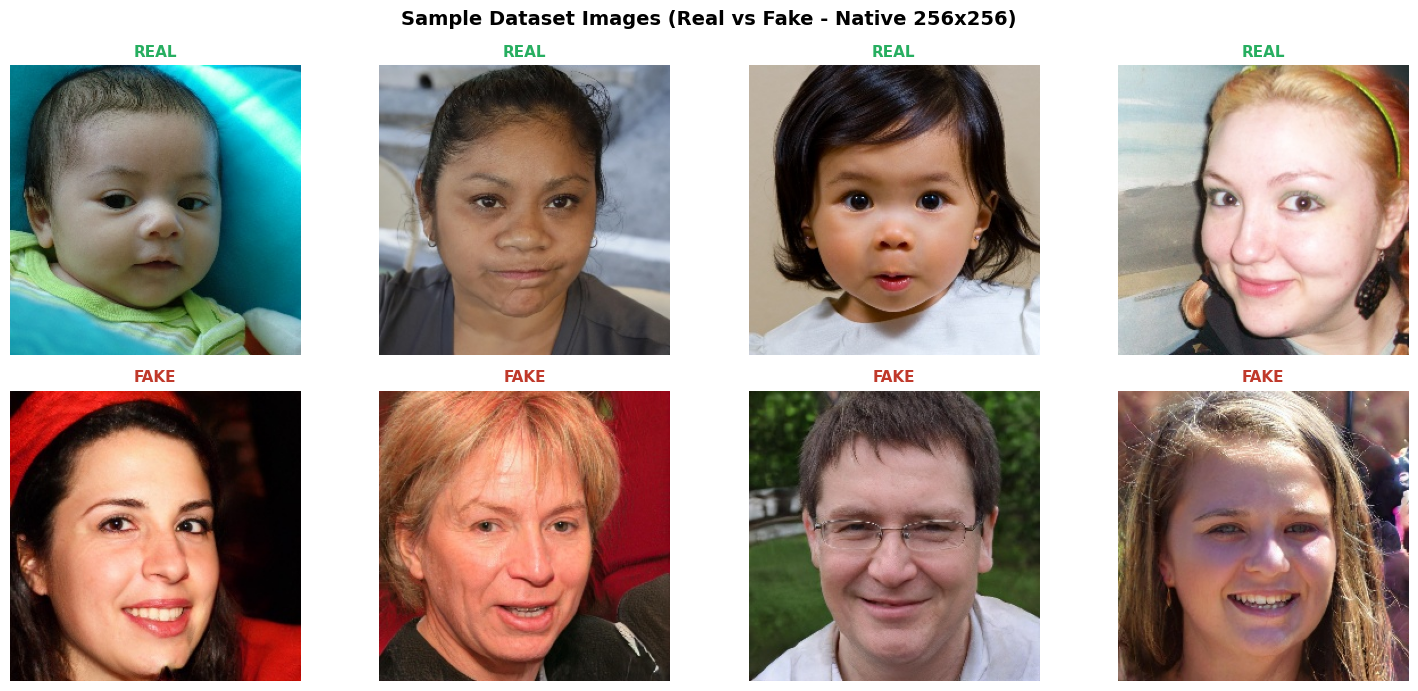

In [5]:
# ==============================================================================
# 4. VISUAL SAMPLE GRID (REAL VS FAKE)
# ==============================================================================
def display_sample_grid(dataset_path, num_samples=8, img_size=256):
    real_dir = os.path.join(dataset_path, "train", "real")
    fake_dir = os.path.join(dataset_path, "train", "fake")
    
    if not os.path.exists(real_dir) or not os.path.exists(fake_dir):
        print(f"[!] Directories not found:\n  {real_dir}\n  {fake_dir}")
        return
        
    valid_exts = ('.jpg', '.jpeg', '.png', '.webp')
    real_files = [
        os.path.join(real_dir, f) for f in os.listdir(real_dir)
        if f.lower().endswith(valid_exts)
    ][:num_samples // 2]
    
    fake_files = [
        os.path.join(fake_dir, f) for f in os.listdir(fake_dir)
        if f.lower().endswith(valid_exts)
    ][:num_samples // 2]
    
    samples = [(f, "REAL") for f in real_files] + [(f, "FAKE") for f in fake_files]
    if not samples:
        print("[!] No sample images found to display.")
        return
        
    num_total = len(samples)
    ncols = min(4, num_total)
    nrows = (num_total + ncols - 1) // ncols
    
    plt.figure(figsize=(15, 3.5 * nrows))
    for idx, (fpath, label) in enumerate(samples):
        with Image.open(fpath) as img:
            plt.subplot(nrows, ncols, idx + 1)
            plt.imshow(img)
            plt.axis("off")
            
            color = '#27ae60' if label == "REAL" else '#c0392b'
            plt.title(f"{label}", fontsize=11, fontweight='bold', color=color)
            
    current_size = globals().get('IMG_SIZE', img_size)
    plt.suptitle(f"Sample Dataset Images (Real vs Fake - Native {current_size}x{current_size})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_sample_grid(DATASET_PATH, num_samples=8)
